In [282]:
import os
import pandas as pd
import numpy as np
import matplotlib as mpl
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report
from sklearn.metrics import confusion_matrix


In [283]:
df=pd.read_csv('WineQT.csv')
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [284]:
df.shape

(1143, 13)

In [285]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality', 'Id'],
      dtype='str')

In [286]:
df['quality'].unique()

array([5, 6, 7, 4, 8, 3])

In [287]:
df['quality_cat']=df['quality'].apply(lambda y_value: 1 if y_value>=7 else 0)

In [288]:
df[['fixed acidity','volatile acidity','citric acid']].head()

,fixed acidity,volatile acidity,citric acid
0,7.4,0.70,0.00
1,7.8,0.88,0.00
2,7.8,0.76,0.04
3,11.2,0.28,0.56
4,7.4,0.70,0.00


In [289]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
quality_cat             0
dtype: int64

In [290]:
df.duplicated().sum()

0

In [291]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,quality_cat
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043,804.969379,0.139108
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824,463.997116,0.346210
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000,0.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000,411.000000,0.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000,794.000000,0.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000,1209.500000,0.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1597.000000,1.000000


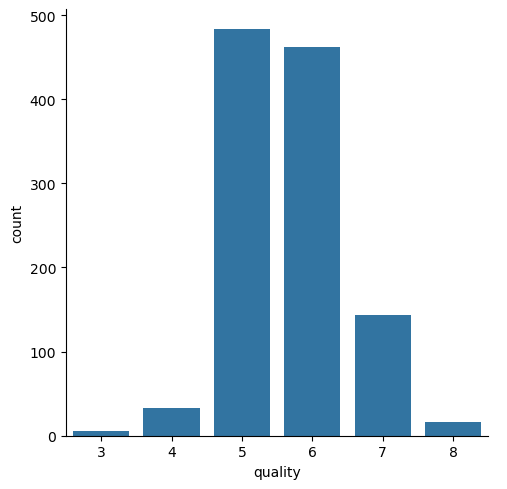

In [292]:
sns.catplot(x='quality', data = df, kind = 'count')

<Axes: xlabel='quality', ylabel='volatile acidity'>

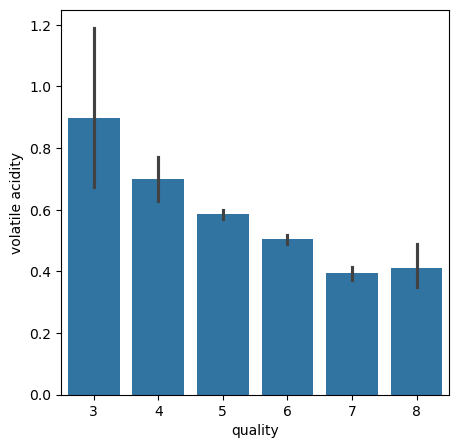

In [293]:
plot = plt.figure(figsize=(5,5))
sns.barplot(x='quality', y = 'volatile acidity', data = df)

<Axes: xlabel='quality', ylabel='citric acid'>

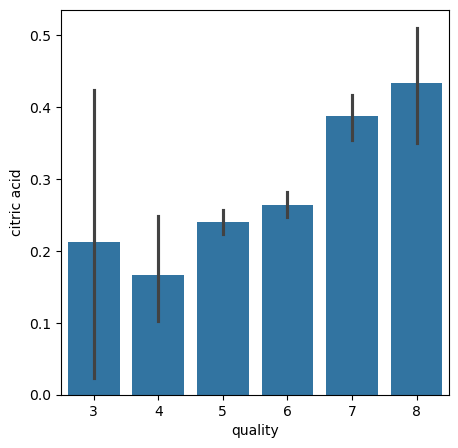

In [294]:
plot = plt.figure(figsize=(5,5))
sns.barplot(x='quality', y = 'citric acid', data = df)

<Axes: >

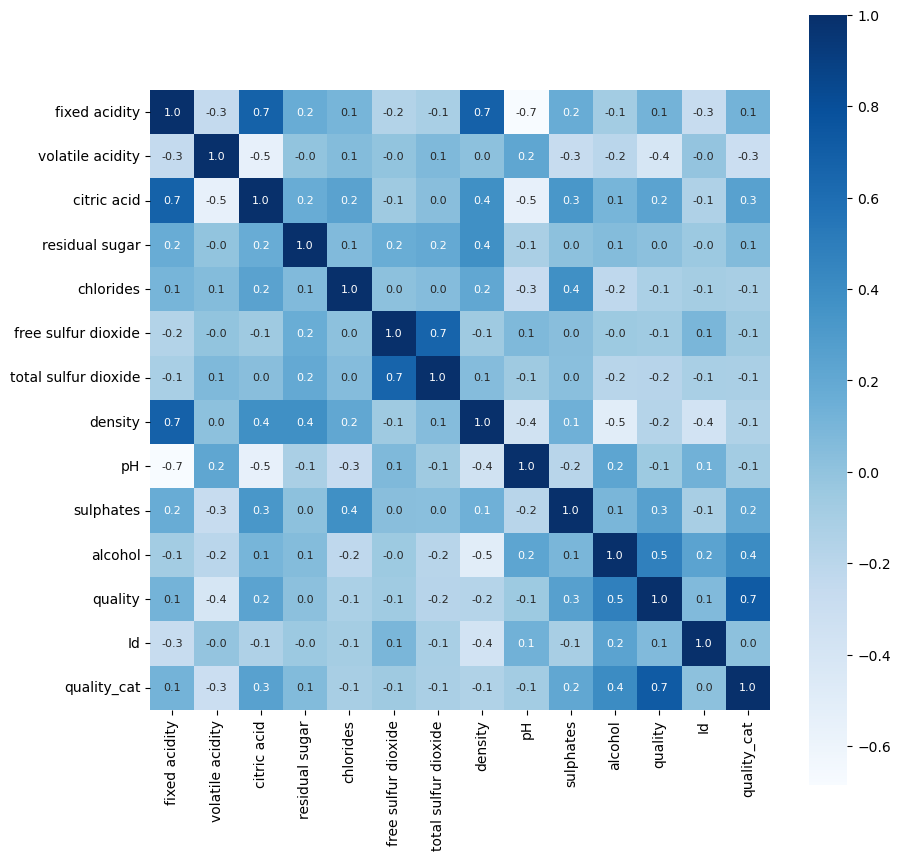

In [295]:
correlation = df.corr()
plt.figure(figsize=(10,10))
sns.heatmap(correlation, cbar=True, square=True, fmt = '.1f', annot = True, annot_kws={'size':8}, cmap = 'Blues')

In [296]:
y = df['quality'].apply(lambda y_value: 1 if y_value>=7 else 0)
x=df.drop(['quality','quality_cat','Id'], axis=1).to_numpy()
x_train, x_test, y_train, y_test= train_test_split(x,y,test_size=0.2, random_state=55,stratify=y)
scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)
def compute_metrics(model):
    model.fit(x_train, y_train)
    predictions=model.predict(x_test)

    print("Accuracy:", accuracy_score(y_test, predictions))


Logistic Regression Model

In [297]:
log_model=LogisticRegression(max_iter=5000)
log_model_acc=compute_metrics(log_model)

Accuracy: 0.868995633187773


KNN Model

In [298]:
knn_model_acc=compute_metrics(KNeighborsClassifier(n_neighbors=5))

Accuracy: 0.868995633187773


SVM Model

In [299]:
svc_acc=compute_metrics(SVC())
svc_acc

Accuracy: 0.8820960698689956


Decision Tree Classifier Model

In [300]:
from sklearn.tree import DecisionTreeClassifier
compute_metrics(DecisionTreeClassifier())


Accuracy: 0.8602620087336245


Random Forest Classifier Model

In [301]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=10,
    random_state=55
)

compute_metrics(rf)

Accuracy: 0.9082969432314411


XGB Model

In [302]:
from xgboost import XGBClassifier
xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    random_state=55
)

compute_metrics(xgb)

Accuracy: 0.9126637554585153


Catboost Model

In [303]:
from catboost import CatBoostClassifier
compute_metrics(CatBoostClassifier(iterations=300,
    learning_rate=0.05,
    depth=4,
    random_state=55,
    verbose=0))

Accuracy: 0.9039301310043668


Gradient Boosting Algorithm

In [304]:
from sklearn.ensemble import GradientBoostingClassifier
compute_metrics(GradientBoostingClassifier())

Accuracy: 0.9170305676855895


In [305]:
input_data = (7.5,0.5,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.8,10.5)

input_data_as_numpy_array = np.asarray(input_data)
input_data_reshaped = input_data_as_numpy_array.reshape(1,-1)
input_data_scaled = scaler.transform(input_data_reshaped)

prediction = log_model.predict(input_data_scaled)
print(prediction)


if (prediction[0]==1):
  print('Good Quality Wine')
else:
  print('Bad Quality Wine')

[0]
Bad Quality Wine


In [306]:
check=(11.2, 0.28, 0.56, 1.9, 0.075, 17.0, 60.0, 0.9980, 3.16, 0.58, 9.8)
check_as_numpy_array = np.asarray(check)
input_data_reshaped = check_as_numpy_array.reshape(1,-1)
input_data_scaled = scaler.transform(input_data_reshaped)

prediction = log_model.predict(input_data_scaled)
print(prediction)


[0]
